# Fine-tune MedForge on the BraTS Deepfake Dataset

This notebook trains a **real vs fake** detector on the **full** BraTS deepfake dataset, then provides a simple inference function for a new scan.

**No patient leakage:** we split by BraTS volume / patient ID **before** any fake tumors are generated. Slices from the same patient never appear in train, validation, or test. The test set is used **once**, after the best checkpoint is chosen on validation.

**Positive class = Fake (1). Negative class = Real (0).**

Official MedForge pieces on Hugging Face:
- `RichardChenZH/MedForge-90K` is the **dataset** (90K real/fake medical images)
- `RichardChenZH/MedForge-Reasoner` is the **8B** vision-language model trained on that dataset



## 0. Install and imports

In [1]:
%pip install -q numpy matplotlib pillow nibabel h5py scikit-learn tqdm
# CUDA 12.4 build so training runs on the NVIDIA GPU (Quadro P4000)
%pip install -q torch torchvision --index-url https://download.pytorch.org/whl/cu124


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import re
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import nibabel as nib
import h5py
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

%matplotlib inline

random.seed(42)
np.random.seed(42)
torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)


c:\Users\Mohamed\AppData\Local\Programs\Python\Python311\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Paths and settings

In [3]:
if Path("ai/dataset").exists():
    os.chdir("ai")

data_root = Path("dataset")
save_path = Path("medforge_braTS_finetuned.pth")

IMG_SIZE = 256
BATCH_SIZE = 8           # 8GB VRAM (ResNet-50 + mask head); try 16 if no OOM
EPOCHS = 10               # full dataset, all patients / all slices
LR = 1e-4
NUM_WORKERS = 0         # Windows + Jupyter hangs if this is > 0

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
    vram = torch.cuda.get_device_properties(0).total_memory / 1024**3
    print(f"VRAM: {vram:.1f} GB")
    torch.backends.cudnn.benchmark = True
else:
    print("WARNING: CUDA not found, training will run on CPU (slow).")
    print("Re-run the install cell, then restart the kernel.")
print("dataset folder:", data_root.resolve(), "| exists:", data_root.exists())

for split in ["train", "val", "test"]:
    for kind in ["real", "fake"]:
        n = len(list((data_root / split / kind).glob("*.png"))) if data_root.exists() else 0
        print(f"  {split}/{kind}: {n} images")

device: cuda
GPU: Quadro P4000
VRAM: 8.0 GB
dataset folder: C:\My-Folders\My Projects\Graduation Project\MedShield-AI\ai\dataset | exists: True
  train/real: 16005 images
  train/fake: 16005 images
  val/real: 3401 images
  val/fake: 3401 images
  test/real: 3470 images
  test/fake: 3470 images


## 2. Check the patient-level 70 / 15 / 15 split

The real/fake images are built in `brats_medical_deepfake_dataset.ipynb`. This cell only checks that **no patient ID** appears in more than one of train / val / test.


In [4]:
# Dataset is built in brats_medical_deepfake_dataset.ipynb (smart inpainting).
# Here we only check that patient IDs do not overlap across train / val / test.


def patient_id_from_name(name):
    m = re.search(r"volume_(\d+)", str(name))
    return m.group(1) if m else Path(name).stem


assert data_root.exists(), "run the data-prep notebook first (ai/dataset is missing)"

ids = {"train": set(), "val": set(), "test": set()}
for split in ["train", "val", "test"]:
    for kind in ["real", "fake"]:
        folder = data_root / split / kind
        n = len(list(folder.glob("*.png"))) if folder.exists() else 0
        print(f"{split}/{kind}: {n} images")
        if folder.exists():
            for p in folder.glob("*.png"):
                ids[split].add(patient_id_from_name(p.name))

print("train patients:", len(ids["train"]),
      " val:", len(ids["val"]),
      " test:", len(ids["test"]))
print("overlaps train-val / train-test / val-test:",
      len(ids["train"] & ids["val"]),
      len(ids["train"] & ids["test"]),
      len(ids["val"] & ids["test"]))
assert len(ids["train"]) > 0 and len(ids["val"]) > 0 and len(ids["test"]) > 0
assert len(ids["train"] & ids["val"]) == 0
assert len(ids["train"] & ids["test"]) == 0
assert len(ids["val"] & ids["test"]) == 0
print("patient split is clean. Fake = 1, Real = 0.")


train/real: 16005 images
train/fake: 16005 images
val/real: 3401 images
val/fake: 3401 images
test/real: 3470 images
test/fake: 3470 images
train patients: 258  val: 55  test: 56
overlaps train-val / train-test / val-test: 0 0 0
patient split is clean. Fake = 1, Real = 0.


## 3. Dataset

Each sample is one FLAIR png + its mask + a label.

- label **0 = Real**
- label **1 = Fake** (the positive class)

Augmentation (horizontal flip) is used on train only, and is applied to the image and the mask together.


In [5]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class BraTSDeepfakeDataset(Dataset):
    def __init__(self, root, split="train", size=256, augment=False):
        self.size = size
        self.augment = augment
        self.samples = []

        root = Path(root)
        for label, kind in [(0, "real"), (1, "fake")]:
            img_dir = root / split / kind
            mask_dir = root / split / f"{kind}_masks"
            for img_path in sorted(img_dir.glob("*.png")):
                mask_path = mask_dir / img_path.name
                self.samples.append((img_path, mask_path, label))

        self.to_tensor = transforms.ToTensor()
        self.normalize = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        img_path, mask_path, label = self.samples[idx]

        img = Image.open(img_path).convert("RGB").resize((self.size, self.size))
        mask = Image.open(mask_path).convert("L").resize((self.size, self.size))

        # simple flip, applied to image and mask together
        if self.augment and random.random() < 0.5:
            img = img.transpose(Image.FLIP_LEFT_RIGHT)
            mask = mask.transpose(Image.FLIP_LEFT_RIGHT)

        img = self.normalize(self.to_tensor(img))
        mask = (self.to_tensor(mask) > 0.5).float()   # 1 x H x W
        label = torch.tensor([label], dtype=torch.float32)
        return img, mask, label

In [6]:
train_set = BraTSDeepfakeDataset(data_root, split="train", size=IMG_SIZE, augment=True)
val_set = BraTSDeepfakeDataset(data_root, split="val", size=IMG_SIZE, augment=False)
test_set = BraTSDeepfakeDataset(data_root, split="test", size=IMG_SIZE, augment=False)

print("full dataset  train:", len(train_set), "  (real/fake balanced)")
print("full dataset  val:  ", len(val_set))
print("full dataset  test: ", len(test_set))
assert len(train_set) > 0, "No training images found."

train_ids = {patient_id_from_name(p) for p, _, _ in train_set.samples}
val_ids = {patient_id_from_name(p) for p, _, _ in val_set.samples}
test_ids = {patient_id_from_name(p) for p, _, _ in test_set.samples}
print("unique patients  train/val/test:", len(train_ids), len(val_ids), len(test_ids))
print("overlap train-val:", train_ids & val_ids)
print("overlap train-test:", train_ids & test_ids)
print("overlap val-test:", val_ids & test_ids)
assert not (train_ids & val_ids) and not (train_ids & test_ids) and not (val_ids & test_ids)

use_gpu = device.type == "cuda"
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=0, pin_memory=use_gpu)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE, shuffle=False,
                        num_workers=0, pin_memory=use_gpu)
test_loader = DataLoader(test_set, batch_size=BATCH_SIZE, shuffle=False,
                         num_workers=0, pin_memory=use_gpu)

img, mask, label = train_set[0]
print("one sample:", tuple(img.shape), tuple(mask.shape), "label:", float(label))
print("train batches / epoch:", len(train_loader), "  (all data)")
print("positive class is Fake=1")


full dataset  train: 32010   (real/fake balanced)
full dataset  val:   6802
full dataset  test:  6940
unique patients  train/val/test: 258 55 56
overlap train-val: set()
overlap train-test: set()
overlap val-test: set()
one sample: (3, 256, 256) (1, 256, 256) label: 0.0
train batches / epoch: 4002   (all data)
positive class is Fake=1


## 4. Model

ResNet-50 encoder (pretrained) + two heads:

- **cls head** → one logit (fake probability after sigmoid)
- **seg head** → a 256×256 anomaly map

Early layers (`conv1`, `layer1`, `layer2`) stay frozen. `layer3`, `layer4` and both heads are trained.

In [7]:
class MedForgeBraTS(nn.Module):
    def __init__(self):
        super().__init__()
        resnet = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)

        self.conv1 = resnet.conv1
        self.bn1 = resnet.bn1
        self.relu = resnet.relu
        self.maxpool = resnet.maxpool
        self.layer1 = resnet.layer1
        self.layer2 = resnet.layer2
        self.layer3 = resnet.layer3
        self.layer4 = resnet.layer4

        # real vs fake
        self.cls_head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.Dropout(0.3),
            nn.Linear(2048, 256),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(256, 1),
        )

        # anomaly mask
        self.seg_head = nn.Sequential(
            nn.Conv2d(2048, 256, kernel_size=1),
            nn.ReLU(),
            nn.Conv2d(256, 64, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.Conv2d(64, 1, kernel_size=1),
        )

    def forward(self, x):
        h, w = x.shape[2], x.shape[3]
        x = self.conv1(x)
        x = self.bn1(x)
        x = self.relu(x)
        x = self.maxpool(x)
        x = self.layer1(x)
        x = self.layer2(x)
        x = self.layer3(x)
        feat = self.layer4(x)                  # B, 2048, H/32, W/32

        cls_logit = self.cls_head(feat)        # B, 1
        seg_logit = self.seg_head(feat)        # B, 1, h', w'
        seg_logit = F.interpolate(seg_logit, size=(h, w), mode="bilinear", align_corners=False)
        return cls_logit, seg_logit

    def freeze_early_layers(self):
        for part in [self.conv1, self.bn1, self.layer1, self.layer2]:
            for p in part.parameters():
                p.requires_grad = False


model = MedForgeBraTS().to(device)
model.freeze_early_layers()

n_total = sum(p.numel() for p in model.parameters())
n_train = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f"parameters: {n_total:,} total, {n_train:,} trainable ({100 * n_train / n_total:.1f}%)")

parameters: 24,704,962 total, 23,260,034 trainable (94.2%)


## 5. Hybrid loss

- **Classification:** binary cross-entropy on the real/fake label
- **Localization:** Dice loss + mask BCE on the anomaly mask (Dice focuses on the injected region; BCE also handles empty real masks)

`loss = cls_loss + dice_loss + mask_bce`

In [8]:
bce = nn.BCEWithLogitsLoss()


def dice_loss(logits, masks, eps=1e-6):
    probs = torch.sigmoid(logits)
    num = 2.0 * (probs * masks).sum(dim=(1, 2, 3))
    den = probs.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3)) + eps
    return (1.0 - num / den).mean()


def hybrid_loss(cls_logit, seg_logit, labels, masks):
    cls_l = bce(cls_logit, labels)
    loc_l = dice_loss(seg_logit, masks) + bce(seg_logit, masks)
    return cls_l + loc_l, cls_l, loc_l

## 6. Train

Training uses **every** image in `dataset/train` and `dataset/val` (no subset). We track train and val **loss**, plus val **accuracy / precision / recall / F1** (Fake = 1).

The **best checkpoint** is the epoch with the highest validation F1 (ties broken by lower val loss). Early stopping ends training if val F1 does not improve. The test set is **not** used here.


In [9]:
optimizer = torch.optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=LR, weight_decay=1e-4,
)
PATIENCE = 4
best_path = Path("medforge_braTS_best.pth")


def run_epoch(loader, train=True):
    if train:
        model.train()
    else:
        model.eval()

    total_loss = 0.0
    n_batches = 0
    all_pred, all_true, all_prob = [], [], []
    dice_vals, iou_vals = [], []

    loop = tqdm(loader, desc="train" if train else "val", leave=False)
    for imgs, masks, labels in loop:
        imgs = imgs.to(device)
        masks = masks.to(device)
        labels = labels.to(device)

        if train:
            optimizer.zero_grad()
            cls_logit, seg_logit = model(imgs)
            loss, _, _ = hybrid_loss(cls_logit, seg_logit, labels, masks)
            loss.backward()
            optimizer.step()
        else:
            with torch.no_grad():
                cls_logit, seg_logit = model(imgs)
                loss, _, _ = hybrid_loss(cls_logit, seg_logit, labels, masks)

        total_loss += loss.item()
        n_batches += 1

        prob = torch.sigmoid(cls_logit).view(-1).detach().cpu()
        pred = (prob >= 0.5).int().tolist()
        true = labels.int().view(-1).cpu().tolist()
        all_prob.extend(prob.tolist())
        all_pred.extend(pred)
        all_true.extend(true)

        with torch.no_grad():
            seg_bin = (torch.sigmoid(seg_logit) >= 0.5).float()
            inter = (seg_bin * masks).sum(dim=(1, 2, 3))
            union = ((seg_bin + masks) > 0).float().sum(dim=(1, 2, 3))
            dice_n = 2.0 * inter
            dice_d = seg_bin.sum(dim=(1, 2, 3)) + masks.sum(dim=(1, 2, 3))
            for i in range(labels.shape[0]):
                if float(labels[i]) < 0.5:
                    continue  # skip empty real masks
                dice_vals.append(float((dice_n[i] / (dice_d[i] + 1e-6)).cpu()))
                iou_vals.append(float((inter[i] / (union[i] + 1e-6)).cpu()))

    return {
        "loss": total_loss / max(n_batches, 1),
        "pred": all_pred,
        "true": all_true,
        "prob": all_prob,
        "dice": float(np.mean(dice_vals)) if dice_vals else float("nan"),
        "iou": float(np.mean(iou_vals)) if iou_vals else float("nan"),
    }


def scores(y_true, y_pred):
    """Fake = 1 is the positive class."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    tp = int(((y_pred == 1) & (y_true == 1)).sum())
    tn = int(((y_pred == 0) & (y_true == 0)).sum())
    fp = int(((y_pred == 1) & (y_true == 0)).sum())
    fn = int(((y_pred == 0) & (y_true == 1)).sum())
    acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    prec = tp / max(tp + fp, 1) if (tp + fp) else 0.0
    rec = tp / max(tp + fn, 1) if (tp + fn) else 0.0
    f1 = 2 * prec * rec / max(prec + rec, 1e-8)
    return {"acc": acc, "prec": prec, "rec": rec, "f1": f1, "tp": tp, "tn": tn, "fp": fp, "fn": fn}


history = []
best_f1 = -1.0
best_val_loss = 1e9
best_epoch = 0
bad_epochs = 0

for epoch in range(1, EPOCHS + 1):
    tr = run_epoch(train_loader, train=True)
    va = run_epoch(val_loader, train=False)
    tr_s = scores(tr["true"], tr["pred"])
    va_s = scores(va["true"], va["pred"])
    row = {
        "epoch": epoch,
        "train_loss": tr["loss"],
        "val_loss": va["loss"],
        "train_acc": tr_s["acc"],
        "val_acc": va_s["acc"],
        "val_prec": va_s["prec"],
        "val_rec": va_s["rec"],
        "val_f1": va_s["f1"],
        "val_dice": va["dice"],
        "val_iou": va["iou"],
        "val_true": va["true"],
        "val_pred": va["pred"],
        "val_prob": va["prob"],
    }
    history.append(row)
    print(
        f"epoch {epoch:02d}/{EPOCHS}  "
        f"train_loss={tr['loss']:.4f}  val_loss={va['loss']:.4f}  "
        f"acc={va_s['acc']:.3f}  prec={va_s['prec']:.3f}  rec={va_s['rec']:.3f}  "
        f"f1={va_s['f1']:.3f}  dice={va['dice']:.3f}  iou={va['iou']:.3f}"
    )

    improved = (va_s["f1"] > best_f1 + 1e-6) or (
        abs(va_s["f1"] - best_f1) < 1e-6 and va["loss"] < best_val_loss
    )
    if improved:
        best_f1 = va_s["f1"]
        best_val_loss = va["loss"]
        best_epoch = epoch
        bad_epochs = 0
        torch.save({
            "model_state": model.state_dict(),
            "img_size": IMG_SIZE,
            "mean": IMAGENET_MEAN,
            "std": IMAGENET_STD,
            "epoch": epoch,
            "metrics": va_s,
        }, best_path)
        torch.save({
            "model_state": model.state_dict(),
            "img_size": IMG_SIZE,
            "mean": IMAGENET_MEAN,
            "std": IMAGENET_STD,
            "epoch": epoch,
            "metrics": va_s,
        }, save_path)
        print(f"  -> saved best checkpoint (val F1={best_f1:.3f})")
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"early stopping at epoch {epoch} (best was epoch {best_epoch})")
            break

ckpt = torch.load(best_path, map_location=device, weights_only=False)
model.load_state_dict(ckpt["model_state"])
print(f"restored best epoch {best_epoch}  val F1={best_f1:.3f}")


train:   0%|          | 0/4002 [00:00<?, ?it/s]

epoch 01/10  train_loss=0.5962  val_loss=0.5617  acc=1.000  prec=1.000  rec=1.000  f1=1.000  dice=0.912  iou=0.840
  -> saved best checkpoint (val F1=1.000)


KeyboardInterrupt: 

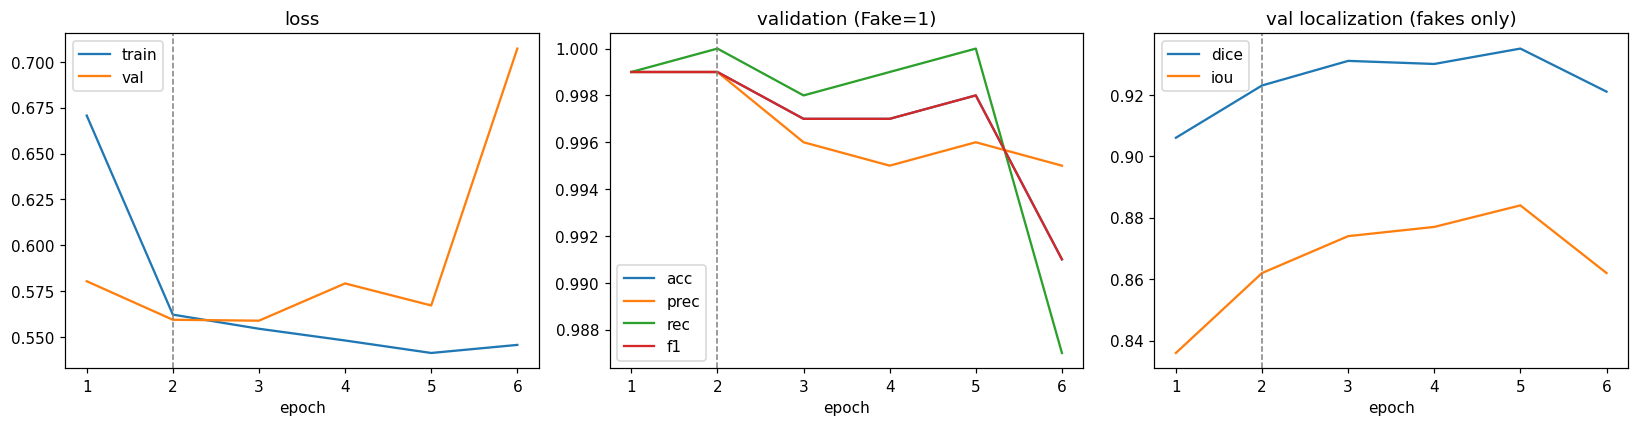

In [ ]:
epochs = [r["epoch"] for r in history]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(epochs, [r["train_loss"] for r in history], label="train")
axes[0].plot(epochs, [r["val_loss"] for r in history], label="val")
axes[0].axvline(best_epoch, color="gray", ls="--", lw=1)
axes[0].set_xlabel("epoch")
axes[0].set_title("loss")
axes[0].legend()

axes[1].plot(epochs, [r["val_acc"] for r in history], label="acc")
axes[1].plot(epochs, [r["val_prec"] for r in history], label="prec")
axes[1].plot(epochs, [r["val_rec"] for r in history], label="rec")
axes[1].plot(epochs, [r["val_f1"] for r in history], label="f1")
axes[1].axvline(best_epoch, color="gray", ls="--", lw=1)
axes[1].set_xlabel("epoch")
axes[1].set_title("validation (Fake=1)")
axes[1].legend()

axes[2].plot(epochs, [r["val_dice"] for r in history], label="dice")
axes[2].plot(epochs, [r["val_iou"] for r in history], label="iou")
axes[2].axvline(best_epoch, color="gray", ls="--", lw=1)
axes[2].set_xlabel("epoch")
axes[2].set_title("val localization (fakes only)")
axes[2].legend()
plt.tight_layout()
plt.show()


## 7. Validation report (best checkpoint)

These numbers are from the **best validation epoch**, not the last epoch. The test set is still untouched.


========  validation (best ckpt)  ========
accuracy : 0.9994
precision: 0.9988   (Fake=1)
recall   : 1.0000   (Fake=1)
F1-score : 0.9994
Dice     : 0.9231   (fakes only)
IoU      : 0.8617   (fakes only)
correct real 1703 / 1705   correct fake 1705 / 1705


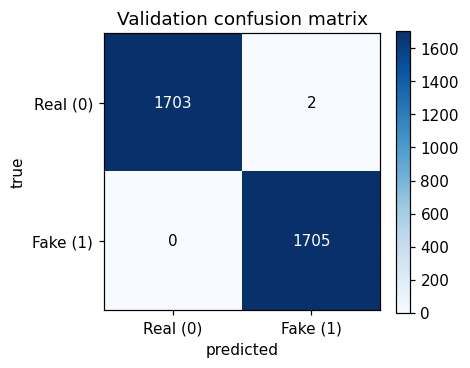

In [ ]:
def plot_confusion(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    fig, ax = plt.subplots(figsize=(4.2, 3.6))
    im = ax.imshow(cm, cmap="Blues")
    ax.set_xticks([0, 1], ["Real (0)", "Fake (1)"])
    ax.set_yticks([0, 1], ["Real (0)", "Fake (1)"])
    ax.set_xlabel("predicted")
    ax.set_ylabel("true")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(int(cm[i, j])), ha="center", va="center",
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    fig.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()
    return cm


va = run_epoch(val_loader, train=False)
va_s = scores(va["true"], va["pred"])
print("========  validation (best ckpt)  ========")
print(f"accuracy : {va_s['acc']:.4f}")
print(f"precision: {va_s['prec']:.4f}   (Fake=1)")
print(f"recall   : {va_s['rec']:.4f}   (Fake=1)")
print(f"F1-score : {va_s['f1']:.4f}")
print(f"Dice     : {va['dice']:.4f}   (fakes only)")
print(f"IoU      : {va['iou']:.4f}   (fakes only)")
print(f"correct real {va_s['tn']} / {va_s['tn']+va_s['fp']}   "
      f"correct fake {va_s['tp']} / {va_s['tp']+va_s['fn']}")
print("==========================================")
plot_confusion(va["true"], va["pred"], "Validation confusion matrix")


## 8. Independent test evaluation

The best checkpoint was chosen on **validation only**. This cell is the first (and only) time we look at the test set.


========  TEST (held-out patients)  ========
n images : 3472   (Fake=1 positive class)
accuracy : 0.9997
precision: 0.9994
recall   : 1.0000
F1-score : 0.9997
ROC-AUC  : 1.0000
PR-AUC   : 1.0000
Dice     : 0.9227   (fakes only)
IoU      : 0.8602   (fakes only)
correct real 1735 / 1736
wrong   real 1 / 1736
correct fake 1736 / 1736
wrong   fake 0 / 1736
confusion matrix [[TN FP] [FN TP]]:
 [[1735    1]
 [   0 1736]]


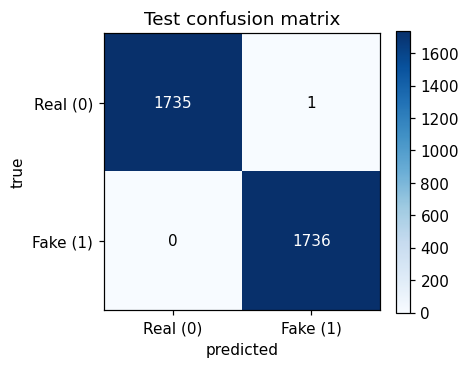

In [ ]:
te = run_epoch(test_loader, train=False)
te_s = scores(te["true"], te["pred"])
y_true = np.array(te["true"])
y_prob = np.array(te["prob"])

roc = roc_auc_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else float("nan")
pr = average_precision_score(y_true, y_prob) if len(np.unique(y_true)) == 2 else float("nan")

print("========  TEST (held-out patients)  ========")
print(f"n images : {len(y_true)}   (Fake=1 positive class)")
print(f"accuracy : {te_s['acc']:.4f}")
print(f"precision: {te_s['prec']:.4f}")
print(f"recall   : {te_s['rec']:.4f}")
print(f"F1-score : {te_s['f1']:.4f}")
print(f"ROC-AUC  : {roc:.4f}")
print(f"PR-AUC   : {pr:.4f}")
print(f"Dice     : {te['dice']:.4f}   (fakes only)")
print(f"IoU      : {te['iou']:.4f}   (fakes only)")
print(f"correct real {te_s['tn']} / {te_s['tn']+te_s['fp']}")
print(f"wrong   real {te_s['fp']} / {te_s['tn']+te_s['fp']}")
print(f"correct fake {te_s['tp']} / {te_s['tp']+te_s['fn']}")
print(f"wrong   fake {te_s['fn']} / {te_s['tp']+te_s['fn']}")
print("============================================")
cm = plot_confusion(te["true"], te["pred"], "Test confusion matrix")
print("confusion matrix [[TN FP] [FN TP]]:\n", cm)


## 9. Forgery localization

Classification says *whether* a scan is fake. The segmentation head should say *where*. Dice / IoU are computed on **fake** images only (real masks are empty, so Dice there is not meaningful).


test fakes: 1736
test localization on 1736 fakes  Dice=0.9227  IoU=0.8602


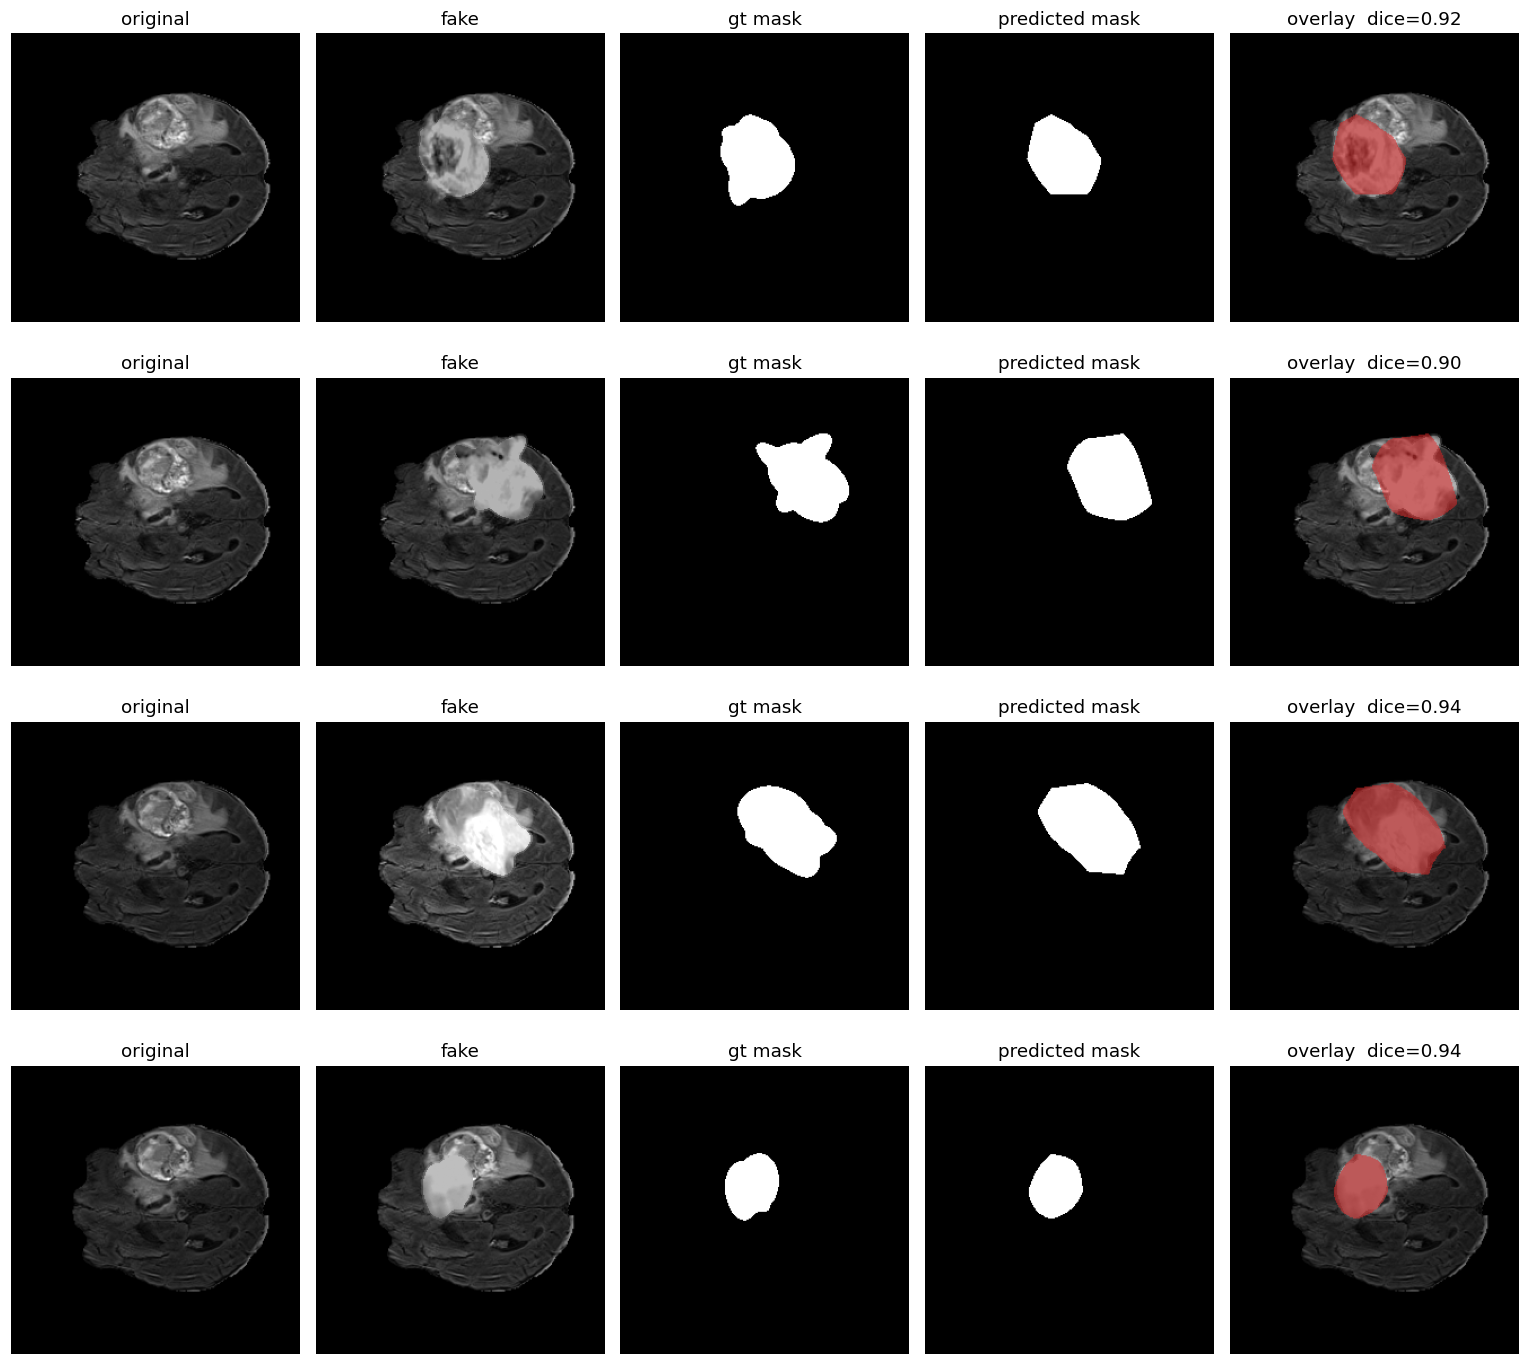

In [ ]:
def loc_one(img_t, mask_t):
    model.eval()
    with torch.no_grad():
        _, seg_logit = model(img_t.unsqueeze(0).to(device))
        pred = (torch.sigmoid(seg_logit)[0, 0] >= 0.5).cpu().numpy()
    gt = mask_t[0].numpy() > 0.5
    inter = np.logical_and(pred, gt).sum()
    union = np.logical_or(pred, gt).sum()
    dice = 2.0 * inter / (pred.sum() + gt.sum() + 1e-6)
    iou = inter / (union + 1e-6)
    return pred, gt, float(dice), float(iou)


fake_idx = [i for i, (_, _, y) in enumerate(test_set.samples) if y == 1]
print("test fakes:", len(fake_idx))
print("Dice / IoU for the full test set are in the test report above.")
print("Here we only plot 4 examples.")

show_n = min(4, len(fake_idx))
fig, axes = plt.subplots(show_n, 5, figsize=(14, 3.2 * show_n))
if show_n == 1:
    axes = np.expand_dims(axes, 0)

for row, i in enumerate(fake_idx[:show_n]):
    img_path, mask_path, _ = test_set.samples[i]
    img_t, mask_t, _ = test_set[i]
    pred, gt, d, iou = loc_one(img_t, mask_t)
    real_img = np.array(Image.open(data_root / "test" / "real" / img_path.name).convert("L"))
    fake_img = np.array(Image.open(img_path).convert("L"))
    overlay = np.stack([fake_img, fake_img, fake_img], axis=-1).astype(np.float32)
    overlay[pred] = overlay[pred] * 0.45 + np.array([220, 40, 40]) * 0.55
    axes[row, 0].imshow(real_img, cmap="gray")
    axes[row, 0].set_title("original")
    axes[row, 1].imshow(fake_img, cmap="gray")
    axes[row, 1].set_title("fake")
    axes[row, 2].imshow(gt, cmap="gray")
    axes[row, 2].set_title("gt mask")
    axes[row, 3].imshow(pred, cmap="gray")
    axes[row, 3].set_title("predicted mask")
    axes[row, 4].imshow(np.clip(overlay / 255.0, 0, 1))
    axes[row, 4].set_title(f"overlay  dice={d:.2f}")
    for c in range(5):
        axes[row, c].axis("off")

plt.tight_layout()
plt.show()


## 10. Inference tool

`analyze_scan()` loads png / jpg / nifti / h5, uses the same preprocessing as training, and returns Real vs Fake plus a localization overlay.


In [ ]:
def load_finetuned(path=save_path):
    try:
        ckpt = torch.load(path, map_location=device, weights_only=False)
    except TypeError:
        ckpt = torch.load(path, map_location=device)
    m = MedForgeBraTS().to(device)
    m.load_state_dict(ckpt["model_state"])
    m.eval()
    print("loaded:", Path(path).resolve(), " epoch:", ckpt.get("epoch"))
    return m


def to_uint8(img):
    img = np.asarray(img, dtype=np.float32)
    if img.size == 0:
        raise ValueError("empty image")
    vmin, vmax = float(img.min()), float(img.max())
    if vmax - vmin < 1e-8:
        return np.zeros(img.shape, dtype=np.uint8)
    img = (img - vmin) / (vmax - vmin)
    return (img * 255).astype(np.uint8)


def load_any_scan(path):
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"file not found: {path}")
    name = str(path).lower()

    if name.endswith(".nii") or name.endswith(".nii.gz"):
        vol = nib.load(str(path)).get_fdata()
        if vol.ndim == 4:
            sl = vol[:, :, vol.shape[2] // 2, 0]
        elif vol.ndim == 3:
            sl = vol[:, :, 0] if vol.shape[-1] <= 4 else vol[:, :, vol.shape[2] // 2]
        else:
            sl = np.asarray(vol)
        return to_uint8(sl)

    if name.endswith(".h5"):
        with h5py.File(path, "r") as f:
            if "image" not in f:
                raise ValueError("h5 file has no 'image' dataset")
            sl = f["image"][:, :, 0]
        return to_uint8(sl)

    img = Image.open(path)
    return np.array(img.convert("L"))


def preprocess_slice(sl, size=IMG_SIZE):
    sl = np.asarray(sl)
    if sl.ndim != 2:
        raise ValueError(f"expected a 2D slice, got shape {sl.shape}")
    if min(sl.shape) < 8:
        raise ValueError(f"slice is too small: {sl.shape}")
    pil = Image.fromarray(to_uint8(sl)).convert("RGB").resize((size, size))
    tensor = transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)(transforms.ToTensor()(pil))
    return tensor.unsqueeze(0), pil


def analyze_scan(path, model=model, device=device, threshold=0.5, show=True):
    """Predict Real vs Fake (Fake=1) and a localization mask."""
    try:
        sl = load_any_scan(path)
        x, pil = preprocess_slice(sl)
    except Exception as e:
        print("could not read scan:", e)
        return {"ok": False, "error": str(e)}

    x = x.to(device)
    model.eval()
    with torch.no_grad():
        cls_logit, seg_logit = model(x)
        fake_prob = float(torch.sigmoid(cls_logit).item())
        mask_prob = torch.sigmoid(seg_logit)[0, 0].cpu().numpy()

    is_fake = fake_prob >= threshold
    label = "fake" if is_fake else "real"
    conf = fake_prob if is_fake else (1.0 - fake_prob)
    message = (
        "FAKE — synthetic manipulation detected"
        if is_fake else
        "REAL — no synthetic manipulation detected"
    )
    print(message)
    print(f"fake probability: {fake_prob*100:.1f}%   confidence: {conf*100:.1f}%")

    if show:
        fig, axes = plt.subplots(1, 3, figsize=(12, 4))
        axes[0].imshow(pil, cmap="gray")
        axes[0].set_title("input")
        axes[0].axis("off")
        axes[1].imshow(mask_prob, cmap="hot", vmin=0, vmax=1)
        axes[1].set_title("predicted localization")
        axes[1].axis("off")
        overlay = np.array(pil.convert("RGB")).astype(np.float32)
        heat = (mask_prob >= 0.5)
        overlay[heat] = overlay[heat] * 0.45 + np.array([220, 40, 40]) * 0.55
        axes[2].imshow(np.clip(overlay / 255.0, 0, 1))
        axes[2].set_title("overlay")
        axes[2].axis("off")
        plt.suptitle(message)
        plt.tight_layout()
        plt.show()

    return {
        "ok": True,
        "label": label,
        "fake_probability": fake_prob,
        "confidence": conf,
        "message": message,
        "mask_prob": mask_prob,
    }


### Try it on a held-out test image

These files were **not** used for training or checkpoint selection.


test real files: 1736  test fake files: 1736
--- real example ---
REAL — no synthetic manipulation detected
fake probability: 0.1%   confidence: 99.9%

--- fake example ---
FAKE — synthetic manipulation detected
fake probability: 100.0%   confidence: 100.0%


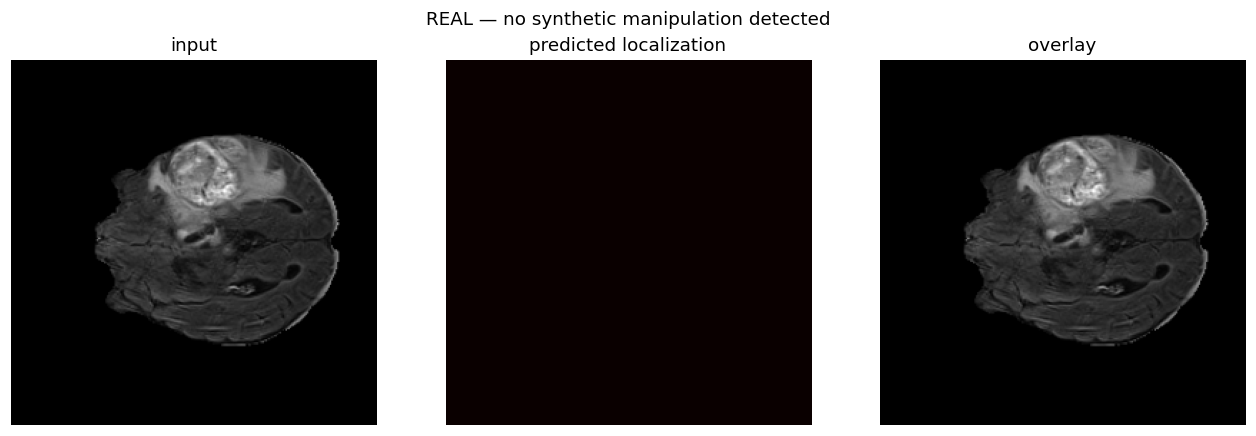

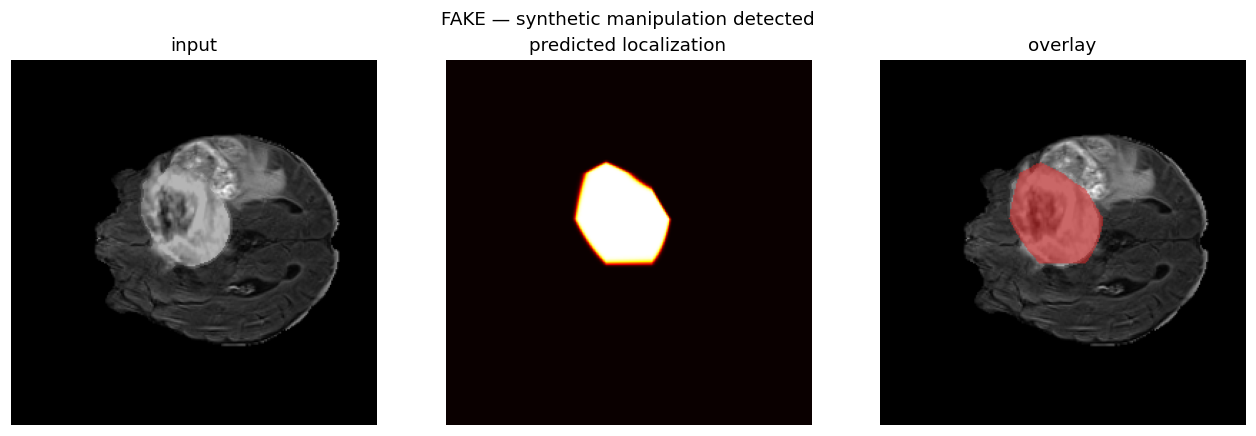

In [ ]:
real_examples = sorted((data_root / "test" / "real").glob("*.png"))
fake_examples = sorted((data_root / "test" / "fake").glob("*.png"))
print("test real files:", len(real_examples), " test fake files:", len(fake_examples))

print("--- real example ---")
analyze_scan(real_examples[0])

print("\n--- fake example ---")
analyze_scan(fake_examples[0])


### Use it on your own file


In [ ]:
# my_file = r"path/to/your/scan.nii.gz"
# analyze_scan(my_file)

print("Ready. Call  analyze_scan('your_file.png')  on a new scan.")
print("Best weights:", Path(save_path).resolve())


Ready. Call  analyze_scan('your_file.png')  on a new scan.
Best weights: C:\My-Folders\My Projects\Graduation Project\MedShield-AI\ai\medforge_braTS_finetuned.pth


## 11. Interactive Gradio demo

This cell launches a small web app so anyone can try the detector.

Upload a **PNG / JPG** slice or a **NIfTI** volume (`.nii` / `.nii.gz`). The app reuses `analyze_scan()` (same preprocessing and the same fine-tuned weights).

Run the cells above first (imports, model class, `analyze_scan`). Then run this cell. A local URL appears below, and `share=True` also tries to create a public demo link.


In [ ]:
%pip install -q gradio

import gradio as gr

# ---------- load the best checkpoint ----------
# after cell 5 the notebook is usually already inside the ai/ folder
weight_path = Path("medforge_braTS_best.pth")
if not weight_path.exists():
    weight_path = Path("ai/medforge_braTS_best.pth")
if not weight_path.exists():
    raise FileNotFoundError(
        "Could not find medforge_braTS_best.pth. "
        "Train the model (section 6) or copy the file next to this notebook."
    )

ui_model = load_finetuned(weight_path)
ui_model.eval()
print("UI model ready:", weight_path.resolve())


def _upload_path(file_obj):
    """Turn a Gradio File value into a normal path string."""
    if file_obj is None:
        return None
    if isinstance(file_obj, dict):
        return file_obj.get("path") or file_obj.get("name")
    return getattr(file_obj, "name", str(file_obj))


def make_heatmap_overlay(pil_img, mask_prob):
    """Paint the localization map on the MRI (same mask as analyze_scan)."""
    base = np.array(pil_img.convert("RGB")).astype(np.float32) / 255.0
    heat = plt.cm.hot(np.clip(mask_prob, 0, 1))[:, :, :3]
    alpha = np.clip(mask_prob, 0, 1)
    alpha = np.where(alpha > 0.12, 0.20 + 0.70 * alpha, 0.0)
    overlay = base * (1.0 - alpha[..., None]) + heat * alpha[..., None]
    return (np.clip(overlay, 0, 1) * 255).astype(np.uint8)


def verdict_html(is_fake):
    if is_fake:
        title = "DEEPFAKE (AI-Generated Manipulation)"
        bg, border, fg = "#fef2f2", "#dc2626", "#7f1d1d"
        tag = "MANIPULATED"
    else:
        title = "REAL (Organic Tumor or Healthy Scan)"
        bg, border, fg = "#ecfdf5", "#0f766e", "#134e4a"
        tag = "AUTHENTIC"
    return f"""
    <div style="padding:18px 20px;border-radius:14px;background:{bg};
                border:2px solid {border};font-family:Inter,Segoe UI,sans-serif;">
      <div style="font-size:12px;letter-spacing:0.14em;font-weight:800;color:{fg};">{tag}</div>
      <div style="font-size:22px;font-weight:800;color:{fg};margin-top:6px;line-height:1.25;">
        {title}
      </div>
    </div>
    """


def confidence_html(fake_prob, conf):
    pct = float(fake_prob) * 100.0
    color = "#dc2626" if fake_prob >= 0.5 else "#0f766e"
    return f"""
    <div style="padding:16px 18px;border-radius:14px;background:#ffffff;
                border:1px solid #d5e3ea;font-family:Inter,Segoe UI,sans-serif;">
      <div style="display:flex;justify-content:space-between;font-weight:700;color:#0f3d4a;">
        <span>Deepfake probability</span>
        <span>{pct:.1f}%</span>
      </div>
      <div style="height:16px;background:#e8eef2;border-radius:999px;margin-top:10px;overflow:hidden;">
        <div style="width:{pct:.1f}%;height:100%;background:{color};border-radius:999px;"></div>
      </div>
      <div style="margin-top:10px;color:#475569;font-size:14px;">
        Confidence in this verdict: <b>{conf*100:.1f}%</b>
        &nbsp;·&nbsp; threshold = 0.50 (Fake = 1)
      </div>
    </div>
    """


def predict_scan(file_obj):
    """Gradio callback: file in -> verdict, confidence bar, heatmap overlay."""
    path = _upload_path(file_obj)
    if path is None:
        empty = "<div style='padding:12px;color:#64748b;'>Upload a scan to start.</div>"
        return empty, empty, None

    # exact same read / preprocess / forward pass as the notebook tool
    result = analyze_scan(path, model=ui_model, device=device, threshold=0.5, show=False)
    if not result.get("ok"):
        err = f"<div style='padding:12px;color:#b91c1c;'>Could not read this file: {result.get('error')}</div>"
        return err, err, None

    sl = load_any_scan(path)
    _, pil = preprocess_slice(sl)
    overlay = make_heatmap_overlay(pil, result["mask_prob"])

    is_fake = result["label"] == "fake"
    return (
        verdict_html(is_fake),
        confidence_html(result["fake_probability"], result["confidence"]),
        overlay,
    )


# a couple of held-out test slices, if the dataset is on disk
example_files = []
for kind in ["real", "fake"]:
    folder = data_root / "test" / kind
    if folder.exists():
        hits = sorted(folder.glob("*.png"))
        if hits:
            example_files.append([str(hits[0])])

medical_css = """
.gradio-container {max-width: 1040px !important;}
#medshield-title h1 {letter-spacing: -0.02em;}
"""

with gr.Blocks(
    theme=gr.themes.Soft(primary_hue="teal", secondary_hue="slate", neutral_hue="slate"),
    css=medical_css,
    title="MedShield-AI",
) as demo:
    with gr.Row(elem_id="medshield-title"):
        gr.Markdown(
            """
            # MedShield-AI: Brain MRI Deepfake & Tumor Manipulation Detector
            Upload a **2D PNG/JPG** slice or a **NIfTI** volume (`.nii` / `.nii.gz`).
            The model returns Real vs Deepfake, a probability bar, and a localization heatmap
            of the suspected AI-injected region.
            """
        )

    with gr.Row():
        with gr.Column(scale=4):
            file_in = gr.File(
                label="Upload a brain MRI  (PNG, JPG, NIfTI)",
                file_types=[".png", ".jpg", ".jpeg", ".nii", ".gz", ".nii.gz"],
                type="filepath",
            )
            run_btn = gr.Button("Analyze scan", variant="primary")
            gr.Markdown(
                "NIfTI volumes use the **middle slice**, same as `analyze_scan()`. "
                "Fake = 1 is the positive class. This is a research demo, not a clinical tool."
            )
            if example_files:
                gr.Examples(
                    examples=example_files,
                    inputs=file_in,
                    label="Try a held-out test slice",
                )

        with gr.Column(scale=6):
            verdict_out = gr.HTML(label="Verdict")
            conf_out = gr.HTML(label="Confidence")
            overlay_out = gr.Image(
                label="Localization Overlay (Heatmap)",
                type="numpy",
            )

    run_btn.click(
        fn=predict_scan,
        inputs=file_in,
        outputs=[verdict_out, conf_out, overlay_out],
    )
    file_in.change(
        fn=predict_scan,
        inputs=file_in,
        outputs=[verdict_out, conf_out, overlay_out],
    )

print("Launching the demo. Local URL first, then a public link if share=True succeeds.")
try:
    demo.launch(share=True, show_error=True)
except Exception as err:
    print("Public link failed:", err)
    print("Opening a local-only demo instead.")
    demo.launch(share=False, show_error=True)



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
